# 01 · Data Audit & Cleaning — PCOS Prediction

**Goal of this notebook:** understand the *raw* data's structure and quality, then fix what is broken
(headers, wrong dtypes, missing values) so that the EDA in `02_eda.ipynb` and the models run on a trustworthy table.

**Flow**
1. Load raw data
2. Standardise column names
3. Data dictionary (dtype, null %, fill rate, cardinality)
4. Data type problems
5. Duplicates & identifiers
6. Missing-value analysis
7. Sanity / range checks
8. Cleaning (fix dtypes, impute, drop IDs)
9. Validation & save the cleaned dataset

> Dataset: *Polycystic Ovary Syndrome (PCOS)* clinical data (Kaggle) — target is whether a patient has PCOS.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))          # make `src` importable
from src.data_utils import rename_columns, coerce_numeric_text, ID_COLS, TARGET, TEXT_NUMERIC_COLS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.float_format", "{:,.3f}".format)

ROOT = Path.cwd().parent
RAW = ROOT / "data" / "raw" / "PCOS_data.csv"
OUT = ROOT / "data" / "processed" / "pcos_clean.csv"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Load the raw data

In [2]:
raw = pd.read_csv(RAW)
print(f"Rows    : {raw.shape[0]:,}")
print(f"Columns : {raw.shape[1]}")
print(f"Memory  : {raw.memory_usage(deep=True).sum()/1024:,.1f} KB")
raw.head()

Rows    : 541
Columns : 44
Memory  : 233.5 KB


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of abortions,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),FSH(mIU/mL),LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
0,1,1,0,28,44.600,152.000,19.300,15,78,22,10.480,2,5,7.000,0,0,1.990,1.99,7.950,3.680,2.160,36,30,0.830,0.680,2.07,45.160,17.100,0.570,92.000,0,0,0,0,0,1.000,0,110,80,3,3,18.000,18.000,8.500
1,2,2,0,36,65.000,161.500,24.900,15,74,20,11.700,2,5,11.000,1,0,60.800,1.99,6.730,1.090,6.170,38,32,0.840,3.160,1.53,20.090,61.300,0.970,92.000,0,0,0,0,0,0.000,0,120,70,3,5,15.000,14.000,3.700
2,3,3,1,33,68.800,165.000,25.300,11,72,18,11.800,2,5,10.000,1,0,494.080,494.08,5.540,0.880,6.300,40,36,0.900,2.540,6.63,10.520,49.700,0.360,84.000,0,0,0,1,1,1.000,0,120,80,13,15,18.000,20.000,10.000
3,4,4,0,37,65.000,148.000,29.700,13,72,20,12.000,2,5,4.000,0,0,1.990,1.99,8.060,2.360,3.420,42,36,0.860,16.410,1.22,36.900,33.400,0.360,76.000,0,0,0,0,0,0.000,0,120,70,2,2,15.000,14.000,7.500
4,5,5,0,25,52.000,161.000,20.100,11,72,18,10.000,2,5,1.000,1,0,801.450,801.45,3.980,0.900,4.420,37,30,0.810,3.570,2.26,30.090,43.800,0.380,84.000,0,0,0,1,0,0.000,0,120,80,3,4,16.000,14.000,7.000


## 3. Standardise column names
The raw headers contain stray leading/trailing/double spaces (e.g. `' Age (yrs)'`, `'  I   beta-HCG(mIU/mL)'`) and symbols.
These would break the Streamlit upload step (exact column match), so we map every header to a clean `snake_case` name
using the shared mapping in `src/data_utils.py`.

In [3]:
df = rename_columns(raw)
pd.DataFrame({"raw_name": [repr(x) for x in raw.columns], "clean_name": df.columns}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43
raw_name,'Sl. No','Patient File No.','PCOS (Y/N)',' Age (yrs)','Weight (Kg)','Height(Cm) ','BMI','Blood Group','Pulse rate(bpm) ','RR (breaths/min)','Hb(g/dl)','Cycle(R/I)','Cycle length(days)','Marraige Status (Yrs)','Pregnant(Y/N)','No. of abortions',' I beta-HCG(mIU/mL)','II beta-HCG(mIU/mL)','FSH(mIU/mL)','LH(mIU/mL)','FSH/LH','Hip(inch)','Waist(inch)','Waist:Hip Ratio','TSH (mIU/L)','AMH(ng/mL)','PRL(ng/mL)','Vit D3 (ng/mL)','PRG(ng/mL)','RBS(mg/dl)','Weight gain(Y/N)','hair growth(Y/N)','Skin darkening (Y/N)','Hair loss(Y/N)','Pimples(Y/N)','Fast food (Y/N)','Reg.Exercise(Y/N)','BP _Systolic (mmHg)','BP _Diastolic (mmHg)','Follicle No. (L)','Follicle No. (R)','Avg. F size (L) (mm)','Avg. F size (R) (mm)','Endometrium (mm)'
clean_name,sl_no,patient_file_no,pcos,age_yrs,weight_kg,height_cm,bmi,blood_group,pulse_rate_bpm,resp_rate,hb_g_dl,cycle_ri,cycle_length_days,marriage_yrs,pregnant,n_abortions,beta_hcg_1,beta_hcg_2,fsh,lh,fsh_lh_ratio,hip_inch,waist_inch,waist_hip_ratio,tsh,amh,prl,vit_d3,prg,rbs,weight_gain,hair_growth,skin_darkening,hair_loss,pimples,fast_food,reg_exercise,bp_systolic,bp_diastolic,follicle_l,follicle_r,avg_f_size_l,avg_f_size_r,endometrium


In [4]:
# every column must now be snake_case (lowercase, no spaces)
bad = [col for col in df.columns if col != col.lower() or " " in col]
print("Columns still not clean:", bad or "none ✅")

Columns still not clean: none ✅


## 4. Data dictionary
For each column: data type, non-null count, **null %**, **fill rate** (= 100 − null %), number of unique values and a sample value.

In [5]:
def data_dictionary(d):
    n = len(d)
    out = pd.DataFrame({
        "dtype": d.dtypes.astype(str),
        "non_null": d.notna().sum(),
        "null_count": d.isna().sum(),
        "null_%": d.isna().mean() * 100,
        "fill_rate_%": d.notna().mean() * 100,
        "n_unique": d.nunique(),
        "example": d.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })
    return out

dd = data_dictionary(df)
dd

,dtype,non_null,null_count,null_%,fill_rate_%,n_unique,example
sl_no,int64,541,0,0.000,100.000,541,1
patient_file_no,int64,541,0,0.000,100.000,541,1
pcos,int64,541,0,0.000,100.000,2,0
age_yrs,int64,541,0,0.000,100.000,29,28
weight_kg,float64,541,0,0.000,100.000,117,44.600
height_cm,float64,541,0,0.000,100.000,50,152.000
bmi,float64,541,0,0.000,100.000,157,19.300
blood_group,int64,541,0,0.000,100.000,8,15
pulse_rate_bpm,int64,541,0,0.000,100.000,11,78
resp_rate,int64,541,0,0.000,100.000,8,22


In [6]:
print("Dtype counts:"); print(dd["dtype"].value_counts().to_string())
print("\nColumns with any missing value:"); print(dd.loc[dd.null_count > 0, ["dtype","null_count","null_%","fill_rate_%"]])

Dtype counts:
dtype
int64      23
float64    19
str         2

Columns with any missing value:
                dtype  null_count  null_%  fill_rate_%
marriage_yrs  float64           1   0.185       99.815
fast_food     float64           1   0.185       99.815


## 5. Data type problems
`beta_hcg_2` and `amh` should be numeric but pandas read them as text. Something non-numeric is hiding in them.

In [7]:
for col in TEXT_NUMERIC_COLS:
    as_num = pd.to_numeric(df[col], errors="coerce")
    bad_idx = df.index[as_num.isna() & df[col].notna()]
    print(f"{col:12s} dtype={df[col].dtype} | non-numeric entries: {len(bad_idx)}")
    display(df.loc[bad_idx, ["sl_no", col]])

beta_hcg_2   dtype=str | non-numeric entries: 1


,sl_no,beta_hcg_2
123,124,1.99.


amh          dtype=str | non-numeric entries: 1


,sl_no,amh
305,306,a


**Finding:** one stray value in each — `'1.99.'` (typo, extra full stop) and `'a'` (garbage).
Decision: `'1.99.'` is clearly the number 1.99, so we repair it; `'a'` is unrecoverable, so it becomes `NaN` and is imputed later.

## 6. Duplicates & identifier columns

In [8]:
print("Fully duplicated rows            :", df.duplicated().sum())
print("Duplicates ignoring ID columns   :", df.drop(columns=ID_COLS).duplicated().sum())
for col in ID_COLS:
    print(f"{col:16s} unique = {df[col].nunique()} / {len(df)}  -> {'unique identifier' if df[col].is_unique else 'NOT unique'}")
print("\nID columns carry no medical signal and would only add noise -> they are dropped during cleaning.")

Fully duplicated rows            : 0
Duplicates ignoring ID columns   : 0
sl_no            unique = 541 / 541  -> unique identifier
patient_file_no  unique = 541 / 541  -> unique identifier

ID columns carry no medical signal and would only add noise -> they are dropped during cleaning.


## 7. Missing-value analysis

In [9]:
miss = dd.loc[dd.null_count > 0, ["null_count","null_%","fill_rate_%"]]
# after fixing text-numerics, 'a' will also be a missing value
txt_nan = {col: pd.to_numeric(df[col], errors="coerce").isna().sum() for col in TEXT_NUMERIC_COLS}
print("Effective missing values after numeric coercion:", txt_nan)
miss

Effective missing values after numeric coercion: {'beta_hcg_2': np.int64(1), 'amh': np.int64(1)}


,null_count,null_%,fill_rate_%
marriage_yrs,1,0.185,99.815
fast_food,1,0.185,99.815


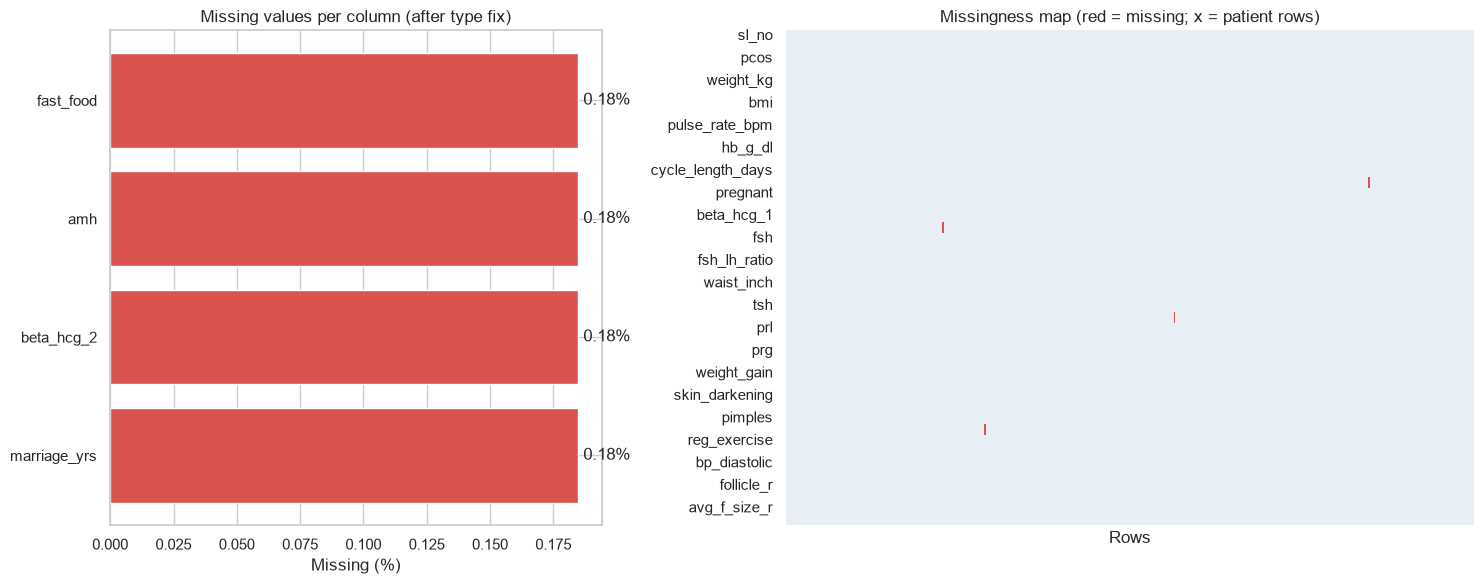

In [10]:
tmp = coerce_numeric_text(df)
m = tmp.isna()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.4]})

# (a) null % per column (only columns with nulls)
null_pct = (m.mean() * 100)
null_pct = null_pct[null_pct > 0].sort_values()
axes[0].barh(null_pct.index, null_pct.values, color="#d9534f")
axes[0].set_xlabel("Missing (%)"); axes[0].set_title("Missing values per column (after type fix)")
for i, v in enumerate(null_pct.values):
    axes[0].text(v, i, f" {v:.2f}%", va="center")

# (b) row/column missingness map
sns.heatmap(m.T, cbar=False, cmap=["#e8eef5", "#d9534f"], ax=axes[1], xticklabels=False)
axes[1].set_title("Missingness map (red = missing; x = patient rows)")
axes[1].set_xlabel("Rows")
plt.tight_layout(); savefig("01_missing_values"); plt.show()

In [11]:
rows_with_na = tmp[m.any(axis=1)]
print(f"Rows with at least one missing value: {len(rows_with_na)} of {len(tmp)} ({len(rows_with_na)/len(tmp):.2%})")
rows_with_na[["sl_no", TARGET] + list(m.columns[m.any()])]

Rows with at least one missing value: 4 of 541 (0.74%)


,sl_no,pcos,marriage_yrs,beta_hcg_2,amh,fast_food
123,124,1,2.000,NaN,19.800,1.000
156,157,0,5.000,1.990,5.270,NaN
305,306,0,9.000,1.990,NaN,0.000
458,459,1,NaN,1.990,6.600,0.000


**Finding:** missingness is tiny — only 4 cells across 4 rows (<0.2 % of rows). The data are not missing in any pattern
(it's isolated entry errors), so dropping rows isn't necessary and would waste scarce data (only 541 rows).

**Imputation strategy**
| Column type | Method | Why |
|---|---|---|
| Continuous (`beta_hcg_2`, `amh`, `marriage_yrs`) | **median** | robust to the skew/outliers seen in hormone levels |
| Binary flag (`fast_food`) | **mode** | keeps the value a valid 0/1 |

## 8. Sanity / range checks (domain knowledge)

In [12]:
checks = {
    "age_yrs": (10, 60), "weight_kg": (25, 150), "height_cm": (120, 200), "bmi": (12, 50),
    "pulse_rate_bpm": (40, 140), "resp_rate": (8, 40), "hb_g_dl": (5, 18),
    "cycle_length_days": (1, 15), "waist_hip_ratio": (0.5, 1.5),
    "bp_systolic": (70, 200), "bp_diastolic": (40, 130), "endometrium": (1, 25),
}
rows = []
for col, (lo, hi) in checks.items():
    s = tmp[col]
    rows.append({"column": col, "min": s.min(), "max": s.max(), "expected_range": f"{lo}-{hi}",
                 "n_out_of_range": int(((s < lo) | (s > hi)).sum())})
pd.DataFrame(rows)

,column,min,max,expected_range,n_out_of_range
0,age_yrs,20.000,48.000,10-60,0
1,weight_kg,31.000,108.000,25-150,0
2,height_cm,137.000,180.000,120-200,0
3,bmi,12.400,38.900,12-50,0
4,pulse_rate_bpm,13.000,82.000,40-140,2
5,resp_rate,16.000,28.000,8-40,0
6,hb_g_dl,8.500,14.800,5-18,0
7,cycle_length_days,0.000,12.000,1-15,1
8,waist_hip_ratio,0.760,0.980,0.5-1.5,0
9,bp_systolic,12.000,140.000,70-200,1


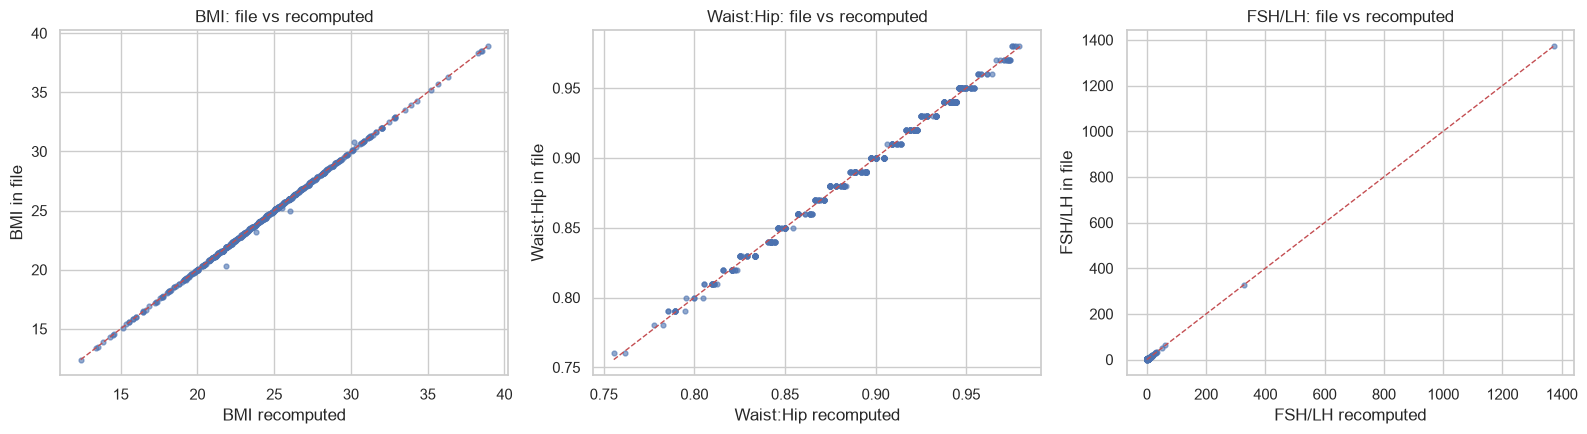

Max |diff| BMI       : 1.575
Max |diff| Waist:Hip : 0.005
Rows where FSH/LH differs >0.5 from recomputed: 0


In [13]:
# internal consistency: BMI vs weight/height, waist:hip ratio vs waist/hip, FSH/LH vs FSH, LH
bmi_calc  = tmp.weight_kg / (tmp.height_cm / 100) ** 2
whr_calc  = tmp.waist_inch / tmp.hip_inch
fshlh_calc = tmp.fsh / tmp.lh
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (x, y, name) in zip(axes, [(bmi_calc, tmp.bmi, "BMI"), (whr_calc, tmp.waist_hip_ratio, "Waist:Hip"),
                                   (fshlh_calc, tmp.fsh_lh_ratio, "FSH/LH")]):
    ax.scatter(x, y, s=12, alpha=.6)
    lim = [min(x.min(), y.min()), max(np.nanmax(x), y.max())]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_xlabel(f"{name} recomputed"); ax.set_ylabel(f"{name} in file"); ax.set_title(f"{name}: file vs recomputed")
plt.tight_layout(); savefig("02_consistency_checks"); plt.show()
print("Max |diff| BMI       :", (bmi_calc - tmp.bmi).abs().max().round(3))
print("Max |diff| Waist:Hip :", (whr_calc - tmp.waist_hip_ratio).abs().max().round(3))
print("Rows where FSH/LH differs >0.5 from recomputed:", int(((fshlh_calc - tmp.fsh_lh_ratio).abs() > 0.5).sum()))

Derived columns (BMI, waist:hip ratio, FSH/LH) agree with their source columns, so the file is internally consistent.
Values that are **biologically impossible** (pulse 13–18 bpm, BP 12/8 mmHg, FSH 5,052 and LH 2,018 mIU/mL) are data-entry errors, not outliers, so they are repaired in the cleaning step below. Values that are merely *extreme but possible* (high prolactin, AMH, β-hCG, …) are kept and examined in the EDA notebook.

## 9. Cleaning

In [14]:
clean = coerce_numeric_text(df.assign(beta_hcg_2=df["beta_hcg_2"].replace({"1.99.": "1.99"})))   # repair typo, 'a' -> NaN
clean = clean.drop(columns=ID_COLS)

# --- physiologically impossible values (data-entry errors) -> treat as missing ---
IMPLAUSIBLE = {
    "pulse_rate_bpm": lambda s: s < 40,       # 13 and 18 bpm are not survivable in an outpatient
    "bp_systolic":    lambda s: s < 60,       # 12 mmHg
    "bp_diastolic":   lambda s: s < 30,       # 8 mmHg
    "fsh":            lambda s: s > 200,      # 5052 mIU/mL (postmenopausal values are ~100)
    "lh":             lambda s: s > 200,      # 2018 mIU/mL
}
flagged = {}
for col, rule in IMPLAUSIBLE.items():
    m_ = rule(clean[col]); flagged[col] = clean.index[m_].tolist()
    print(f"{col:15s} -> {m_.sum()} impossible value(s) set to NaN: {clean.loc[m_, col].tolist()}")
    clean.loc[m_, col] = np.nan

# impute
cont_impute = ["beta_hcg_2", "amh", "marriage_yrs"] + list(IMPLAUSIBLE)
bin_impute = ["fast_food"]
for col in cont_impute:
    med = clean[col].median(); print(f"{col:14s} median = {med:.3f}  (filled {clean[col].isna().sum()})")
    clean[col] = clean[col].fillna(med)
for col in bin_impute:
    mode = clean[col].mode()[0]; print(f"{col:14s} mode   = {mode:.0f}      (filled {clean[col].isna().sum()})")
    clean[col] = clean[col].fillna(mode)

# derived ratio must stay consistent with the repaired FSH / LH
fix_rows = sorted(set(flagged["fsh"]) | set(flagged["lh"]))
clean.loc[fix_rows, "fsh_lh_ratio"] = (clean.loc[fix_rows, "fsh"] / clean.loc[fix_rows, "lh"]).round(2)
print("fsh_lh_ratio recomputed for rows:", fix_rows)

# integer-like columns back to int
for col in ["fast_food", "pulse_rate_bpm", "bp_systolic", "bp_diastolic"]:
    clean[col] = clean[col].round().astype(int)
clean.shape

pulse_rate_bpm  -> 2 impossible value(s) set to NaN: [18, 13]
bp_systolic     -> 1 impossible value(s) set to NaN: [12]
bp_diastolic    -> 1 impossible value(s) set to NaN: [8]
fsh             -> 1 impossible value(s) set to NaN: [5052.0]
lh              -> 1 impossible value(s) set to NaN: [2018.0]
beta_hcg_2     median = 1.990  (filled 0)
amh            median = 3.700  (filled 1)
marriage_yrs   median = 7.000  (filled 1)
pulse_rate_bpm median = 72.000  (filled 2)
bp_systolic    median = 110.000  (filled 1)
bp_diastolic   median = 80.000  (filled 1)
fsh            median = 4.845  (filled 1)
lh             median = 2.280  (filled 1)
fast_food      mode   = 1      (filled 1)
fsh_lh_ratio recomputed for rows: [329, 455]


(541, 42)

## 10. Validation & save

In [15]:
assert clean.isna().sum().sum() == 0, "still has nulls"
assert not clean.duplicated().any()
assert clean[TARGET].isin([0, 1]).all()
assert all(pd.api.types.is_numeric_dtype(clean[col]) for col in clean.columns)
print("✅ no nulls | no duplicates | target is 0/1 | all columns numeric")
print(f"Before: {raw.shape}   ->   After: {clean.shape}  (dropped 2 ID columns)")
print("Repaired readings now within range:", clean.pulse_rate_bpm.min(), "bpm min pulse |", clean.bp_systolic.min(), "min systolic |", round(clean.fsh.max(),1), "max FSH |", round(clean.lh.max(),1), "max LH")
fill = pd.DataFrame({"before_fill_%": dd["fill_rate_%"].reindex(clean.columns),
                     "after_fill_%": clean.notna().mean() * 100})
fill[fill["before_fill_%"] < 100]

✅ no nulls | no duplicates | target is 0/1 | all columns numeric
Before: (541, 44)   ->   After: (541, 42)  (dropped 2 ID columns)
Repaired readings now within range: 70 bpm min pulse | 100 min systolic | 65.4 max FSH | 14.7 max LH


,before_fill_%,after_fill_%
marriage_yrs,99.815,100.000
fast_food,99.815,100.000


In [16]:
OUT.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUT, index=False)
print("Saved ->", OUT.relative_to(ROOT))
clean.head()

Saved -> data/processed/pcos_clean.csv


,pcos,age_yrs,weight_kg,height_cm,bmi,blood_group,pulse_rate_bpm,resp_rate,hb_g_dl,cycle_ri,cycle_length_days,marriage_yrs,pregnant,n_abortions,beta_hcg_1,beta_hcg_2,fsh,lh,fsh_lh_ratio,hip_inch,waist_inch,waist_hip_ratio,tsh,amh,prl,vit_d3,prg,rbs,weight_gain,hair_growth,skin_darkening,hair_loss,pimples,fast_food,reg_exercise,bp_systolic,bp_diastolic,follicle_l,follicle_r,avg_f_size_l,avg_f_size_r,endometrium
0,0,28,44.600,152.000,19.300,15,78,22,10.480,2,5,7.000,0,0,1.990,1.990,7.950,3.680,2.160,36,30,0.830,0.680,2.070,45.160,17.100,0.570,92.000,0,0,0,0,0,1,0,110,80,3,3,18.000,18.000,8.500
1,0,36,65.000,161.500,24.900,15,74,20,11.700,2,5,11.000,1,0,60.800,1.990,6.730,1.090,6.170,38,32,0.840,3.160,1.530,20.090,61.300,0.970,92.000,0,0,0,0,0,0,0,120,70,3,5,15.000,14.000,3.700
2,1,33,68.800,165.000,25.300,11,72,18,11.800,2,5,10.000,1,0,494.080,494.080,5.540,0.880,6.300,40,36,0.900,2.540,6.630,10.520,49.700,0.360,84.000,0,0,0,1,1,1,0,120,80,13,15,18.000,20.000,10.000
3,0,37,65.000,148.000,29.700,13,72,20,12.000,2,5,4.000,0,0,1.990,1.990,8.060,2.360,3.420,42,36,0.860,16.410,1.220,36.900,33.400,0.360,76.000,0,0,0,0,0,0,0,120,70,2,2,15.000,14.000,7.500
4,0,25,52.000,161.000,20.100,11,72,18,10.000,2,5,1.000,1,0,801.450,801.450,3.980,0.900,4.420,37,30,0.810,3.570,2.260,30.090,43.800,0.380,84.000,0,0,0,1,0,0,0,120,80,3,4,16.000,14.000,7.000


## Summary of cleaning decisions
- Renamed 44 messy headers → clean `snake_case`.
- Fixed two numeric columns stored as text (`'1.99.'` repaired, `'a'` → missing).
- Imputed 4 originally-missing cells (median for continuous, mode for the binary flag).
- Found 6 physiologically impossible readings (pulse 13/18, BP 12/8, FSH 5052, LH 2018); set to missing and median-imputed; `fsh_lh_ratio` recomputed for the FSH/LH rows. No rows were dropped.
- Dropped identifier columns `sl_no`, `patient_file_no`.
- No duplicates; derived columns (BMI, waist:hip, FSH/LH) are consistent.
- Extreme-but-plausible values deliberately **kept**; assessed in `02_eda.ipynb`.

**Output:** `data/processed/pcos_clean.csv` (541 rows × 42 columns) → next: `02_eda.ipynb`.